# 03 · Principal component analysis

**Goal.** See which directions separate the countries most, and which subindicators drive them, in each configuration.

* Every subindicator is **standardized** (z-scores), so none dominates because of its spread.
* With 20 countries there are at most 19 components. **Horn's parallel analysis** says how many stand out from noise: each subindicator is shuffled independently 1,000 times, and a component is kept while its eigenvalue beats the 95th percentile of the shuffled ones. In the profile view each shuffled matrix is re-centred per country, so it obeys the same constraint as the real profile data.
* **Loadings** are correlations between a subindicator and a component (−1 to 1).
* Two views of each configuration:
  * **level** – the standardized scores as they are;
  * **profile** – each country's mean z-score removed first, so the PCA sees only its *pattern* of strengths and weaknesses, not its overall level.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from ilia_explore import data as D, pruning as P, pca as PC, clustering as CL, plots as PL, pipeline as PP

PL.setup_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 3)

In [2]:
codebook = D.load_codebook()
fits = {}
for cfg in PP.CONFIGS:
    for mode in PP.MODES:
        X = D.load_processed(cfg)
        Z = PP.prepare(X, mode)
        res = PC.run_pca(Z)
        # profile: shuffled matrices are re-centred per country, like the real ones
        pa = PC.parallel_analysis(Z, n_iter=PP.N_PERM, level_removed=(mode == "profile"))
        fits[(cfg, mode)] = (Z, res, pa)
        out = D.RESULTS / PP.tag(cfg, mode); out.mkdir(parents=True, exist_ok=True)
        k = res.n_components
        pd.DataFrame({"eigenvalue": res.eigenvalues, "explained": res.explained,
                      "cumulative": res.explained.cumsum()}).iloc[:k].to_csv(out / "pca_variance.csv")
        pa.to_csv(out / "parallel_analysis.csv")
        res.scores.iloc[:, :k].to_csv(out / "pca_scores.csv")
        res.loadings.iloc[:, :k].to_csv(out / "pca_loadings.csv")

overview = pd.DataFrame({
    f"{c} · {m}": {"subindicators": Z.shape[1], "PCs above noise": int(pa["retain"].sum()),
                   **{f"PC{i}": res.explained[f"PC{i}"] for i in range(1, 6)},
                   "PC1+PC2": res.explained.iloc[:2].sum()}
    for (c, m), (Z, res, pa) in fits.items()}).T
overview.to_csv(D.RESULTS / "pca_overview.csv")
overview.style.format({**{f"PC{i}": "{:.1%}" for i in range(1, 6)}, "PC1+PC2": "{:.1%}"})

,subindicators,PCs above noise,PC1,PC2,PC3,PC4,PC5,PC1+PC2
A-full · level,86.000000,2.000000,39.5%,11.5%,7.6%,6.7%,4.6%,51.0%
A-full · profile,86.000000,4.000000,17.2%,12.3%,10.8%,9.1%,6.8%,29.4%
A-pruned · level,70.000000,2.000000,35.6%,11.3%,8.0%,6.8%,5.4%,46.9%
A-pruned · profile,70.000000,3.000000,15.9%,12.3%,11.1%,8.4%,7.3%,28.3%
I-full · level,126.000000,2.000000,39.3%,10.2%,7.3%,7.0%,4.6%,49.5%
I-full · profile,126.000000,4.000000,15.5%,13.0%,10.7%,8.9%,6.6%,28.4%
I-pruned · level,106.000000,2.000000,37.5%,10.1%,7.5%,6.8%,4.9%,47.6%
I-pruned · profile,106.000000,4.000000,14.5%,13.2%,10.5%,8.5%,7.0%,27.7%


## Is PC1 just the overall level?

In composite indices PC1 is often a "size" factor: every subindicator loads with the same sign and the country score
on PC1 is close to its simple average. If so, the interesting typology lives in PC2 and beyond, or in the profile view.

In [3]:
rows = {}
for cfg in PP.CONFIGS:
    Z, res, pa = fits[(cfg, "level")]
    L1 = res.loadings["PC1"]
    rows[cfg] = {"corr(PC1, mean z)": np.corrcoef(res.scores["PC1"], Z.mean(axis=1))[0, 1],
                 "share of positive PC1 loadings": (L1 > 0).mean(),
                 "median PC1 loading": L1.median()}
pc1 = pd.DataFrame(rows).T
pc1.to_csv(D.RESULTS / "pc1_as_level.csv")
pc1

,"corr(PC1, mean z)",share of positive PC1 loadings,median PC1 loading
A-full,0.998,0.953,0.627
A-pruned,0.997,0.943,0.601
I-full,0.997,0.944,0.643
I-pruned,0.997,0.943,0.625


## Level view


### A-full · level


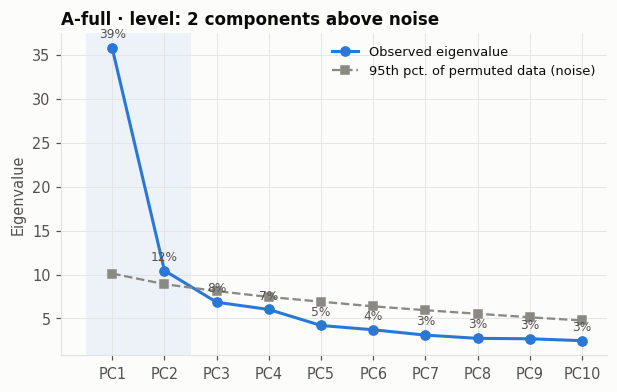

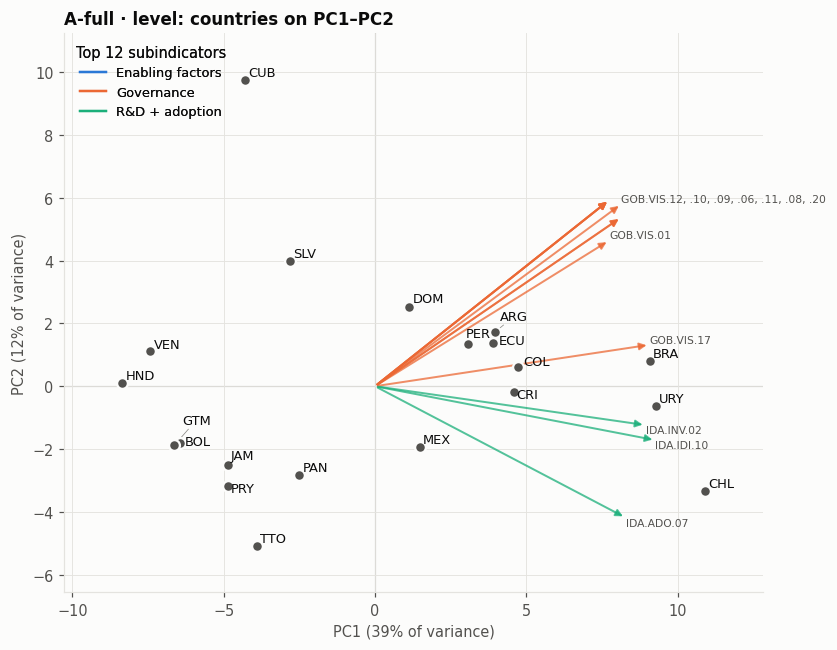

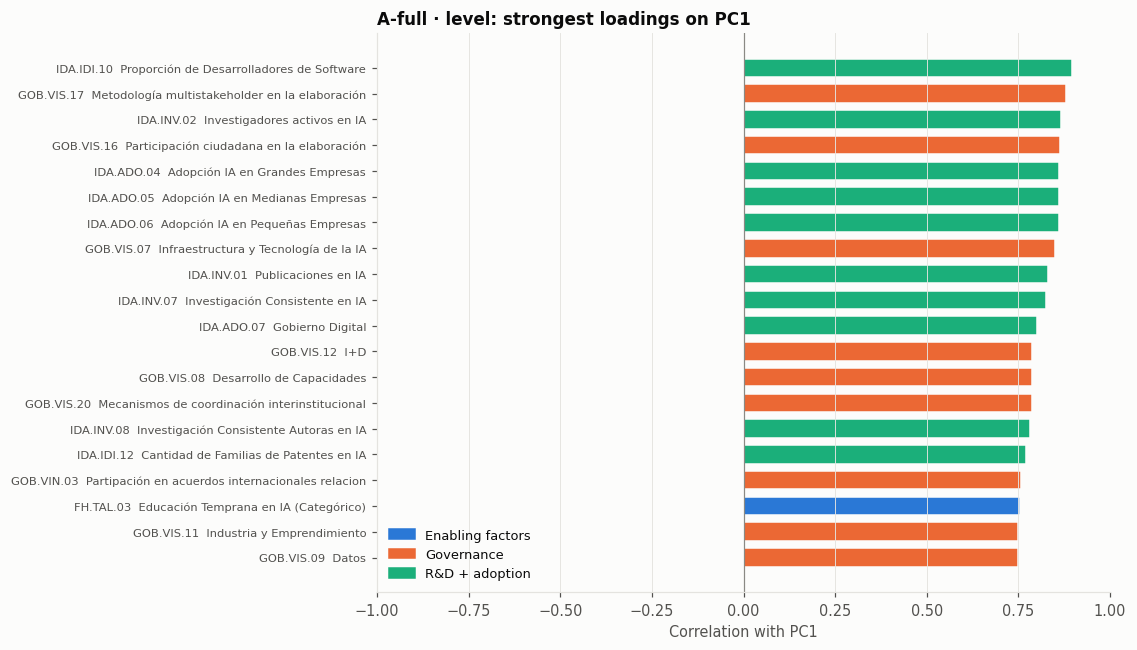

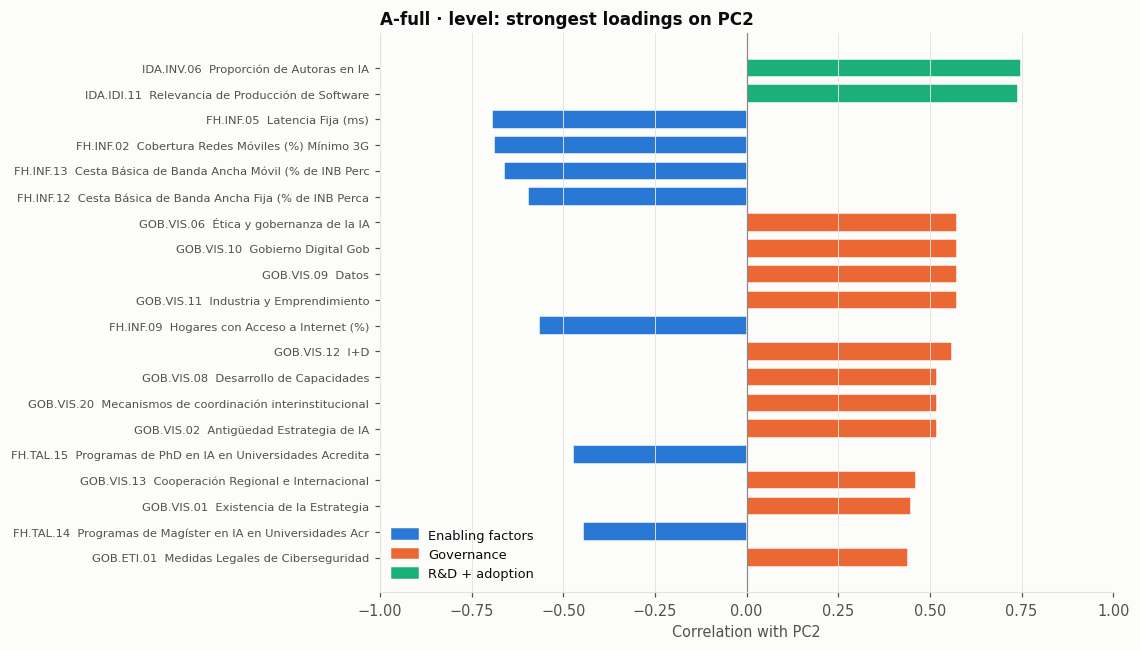

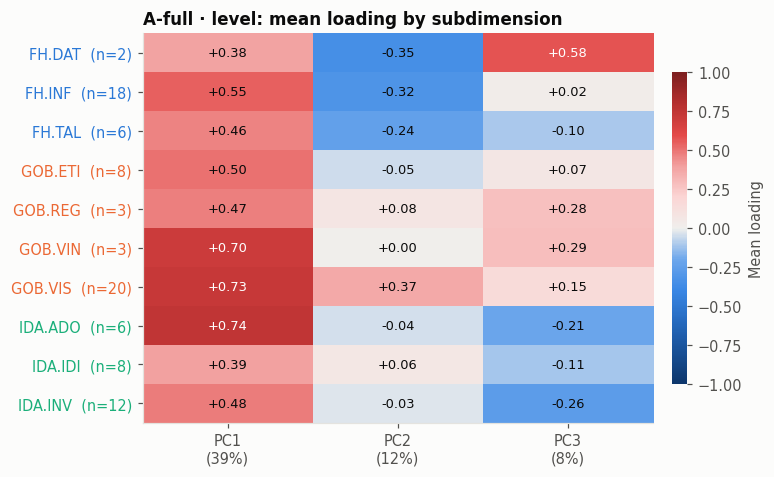


### A-pruned · level


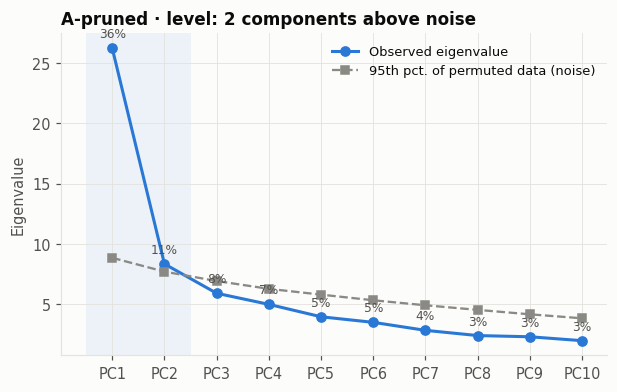

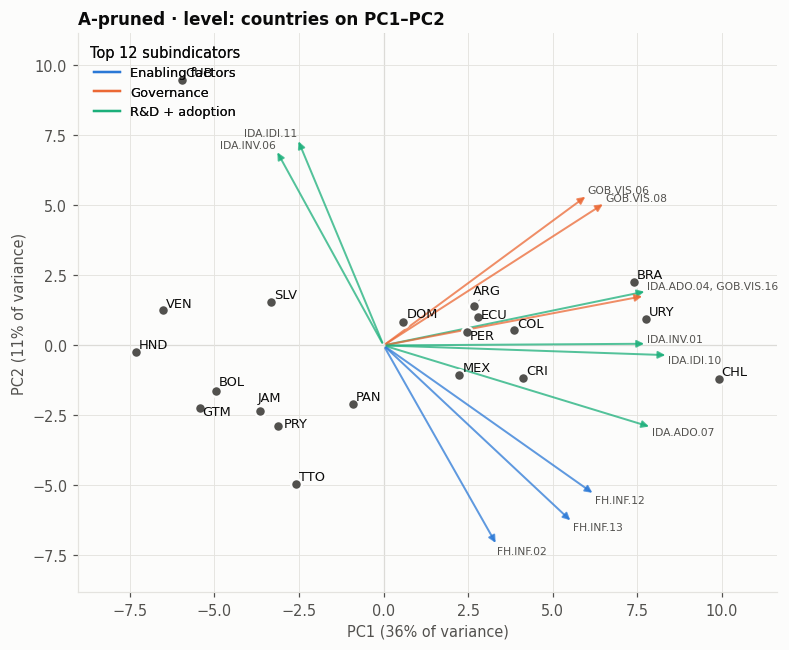

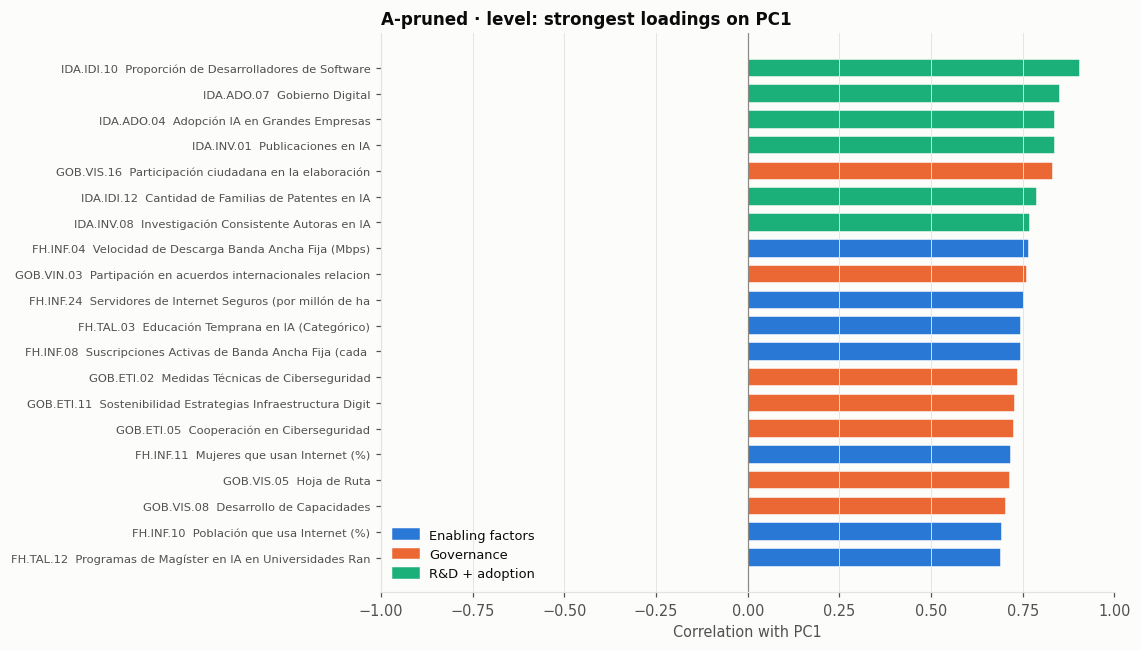

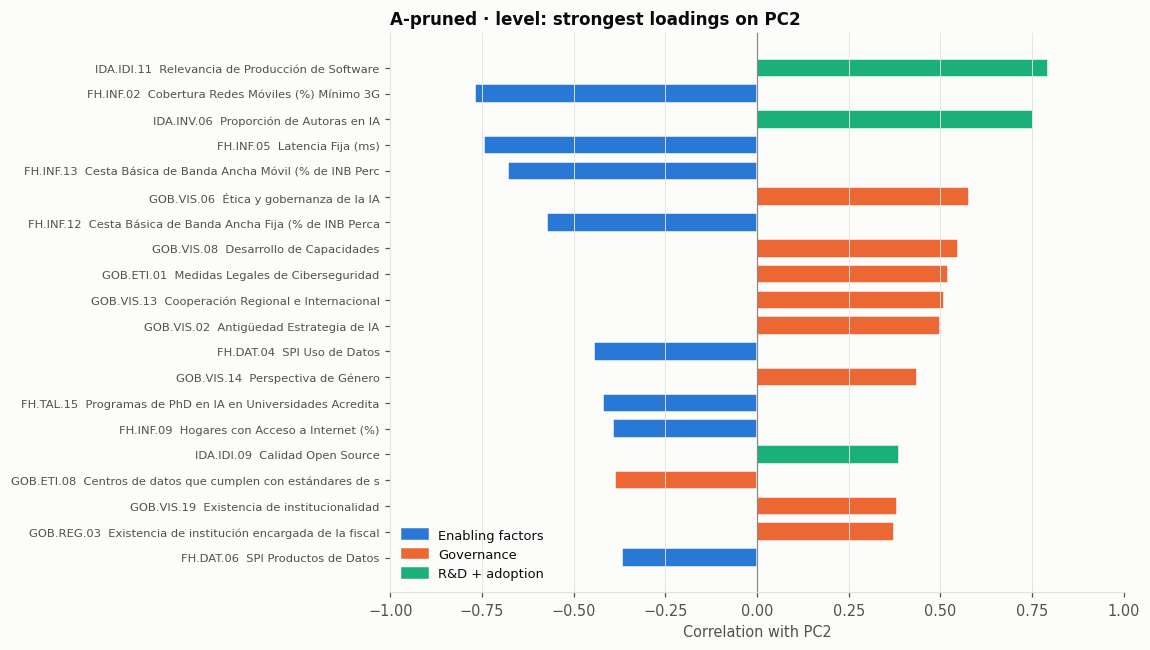

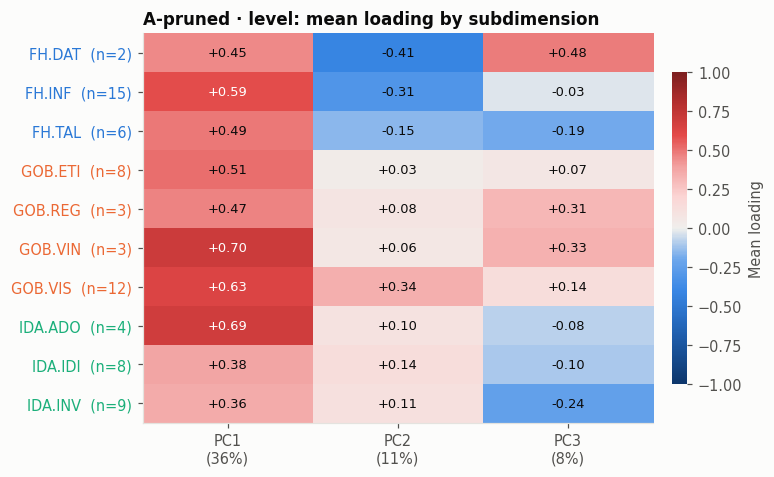


### I-full · level


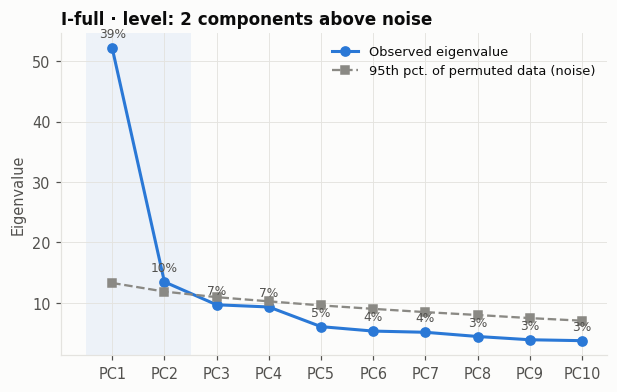

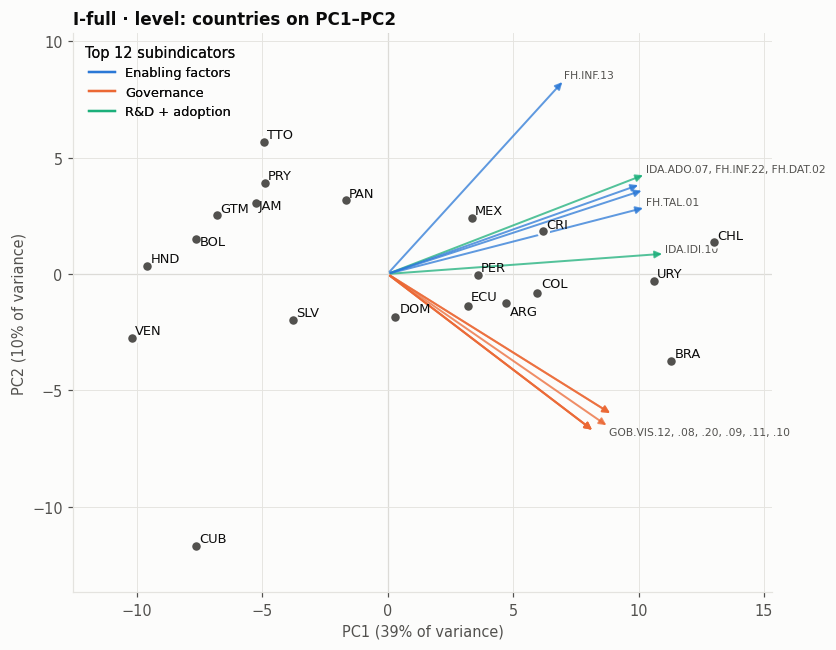

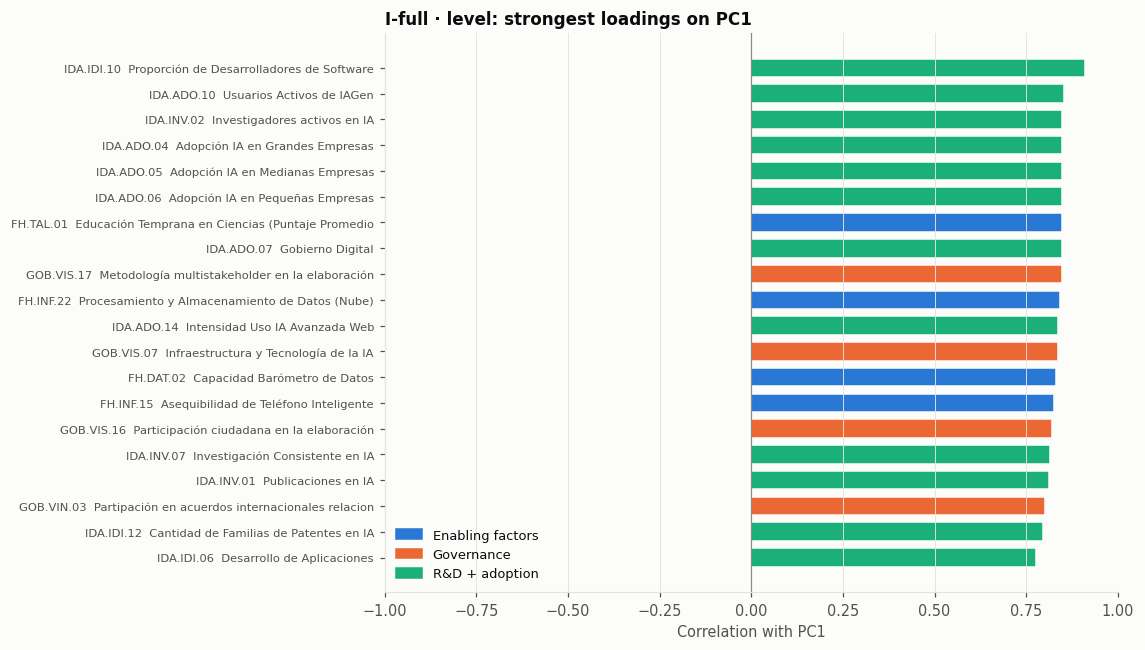

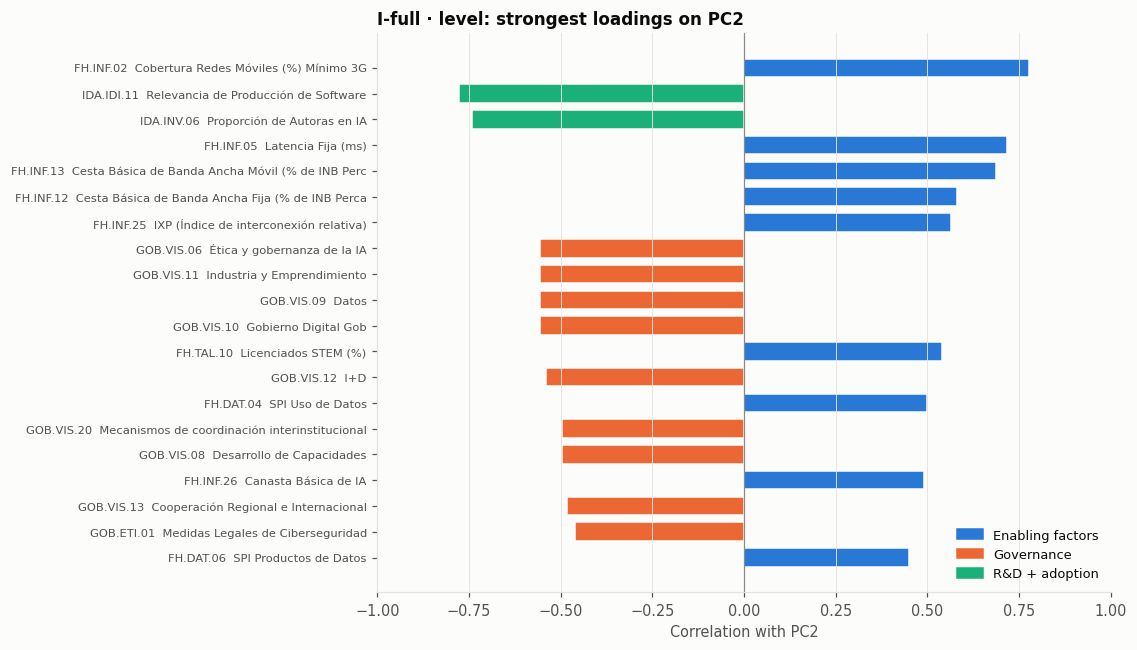

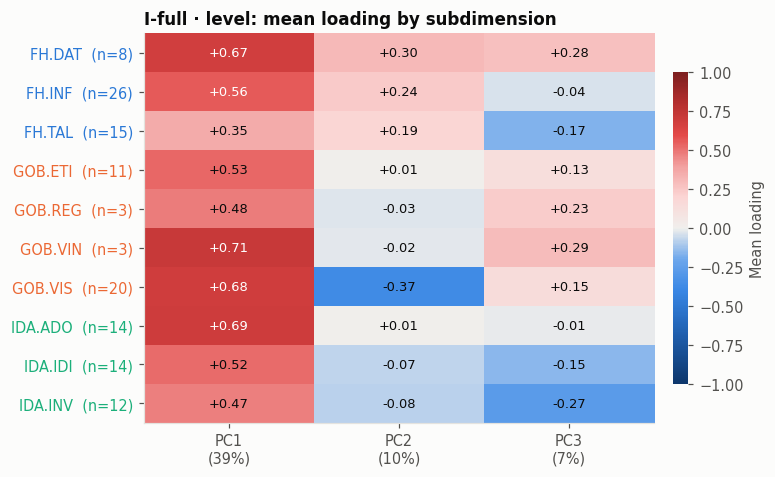


### I-pruned · level


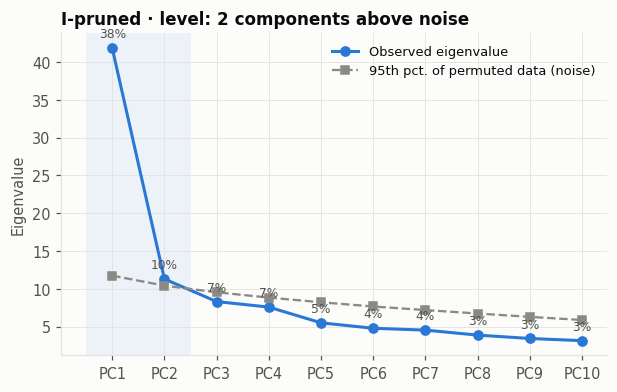

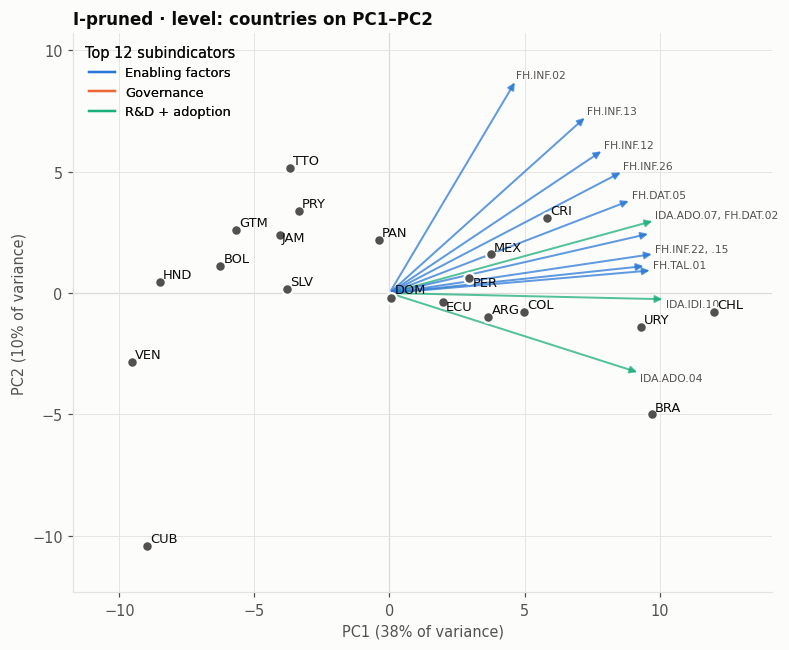

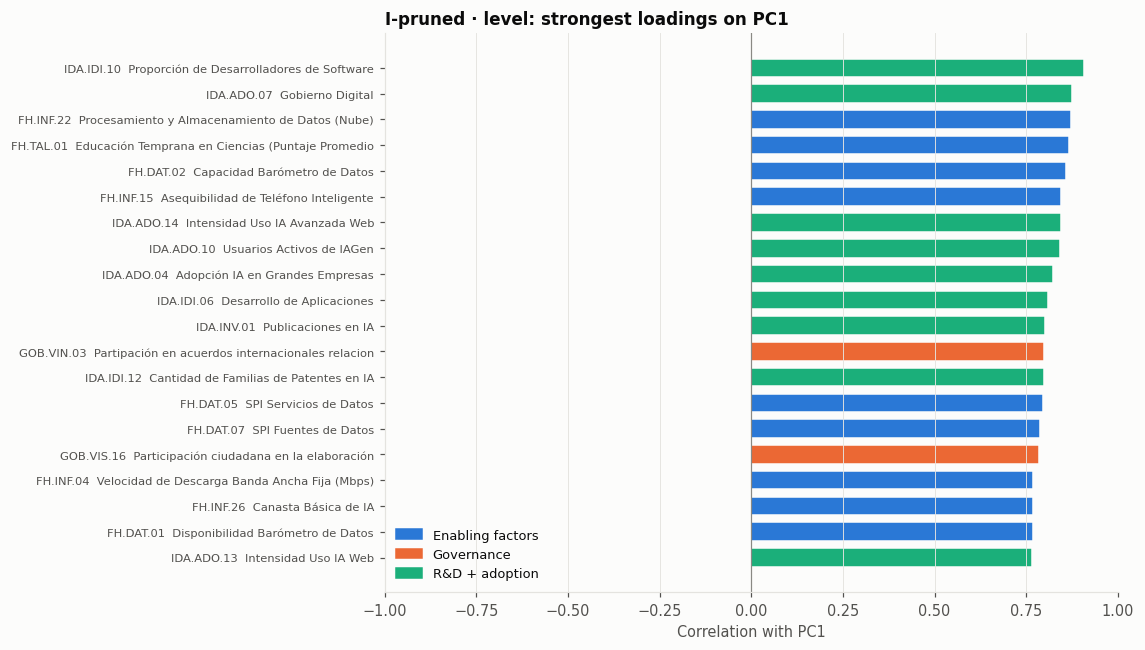

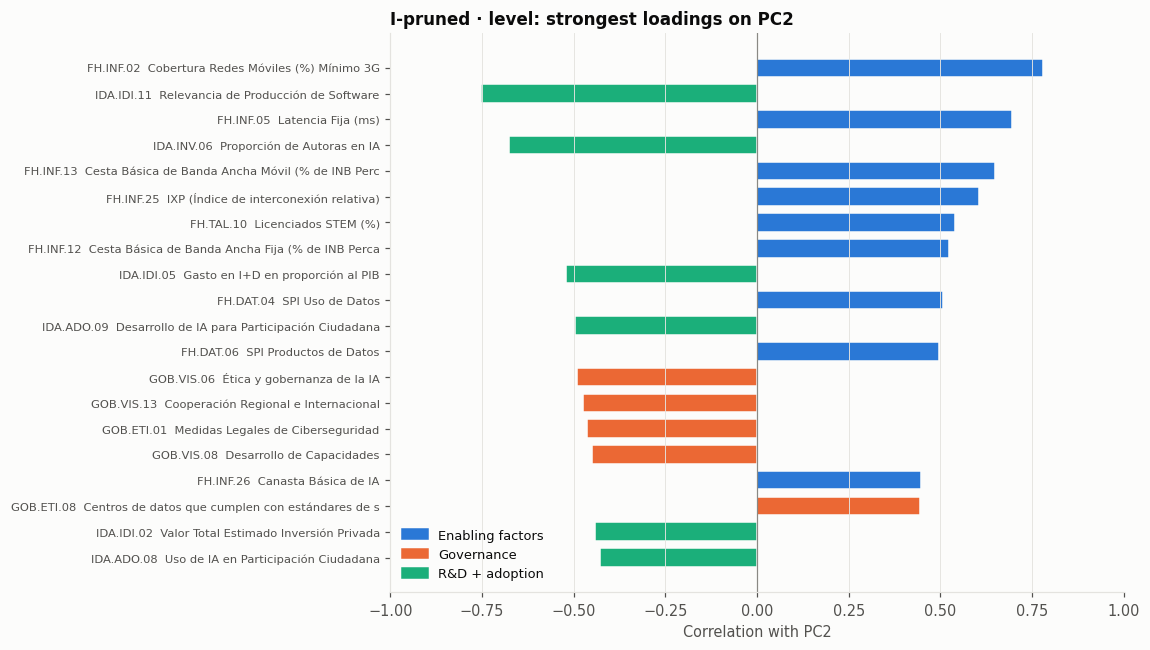

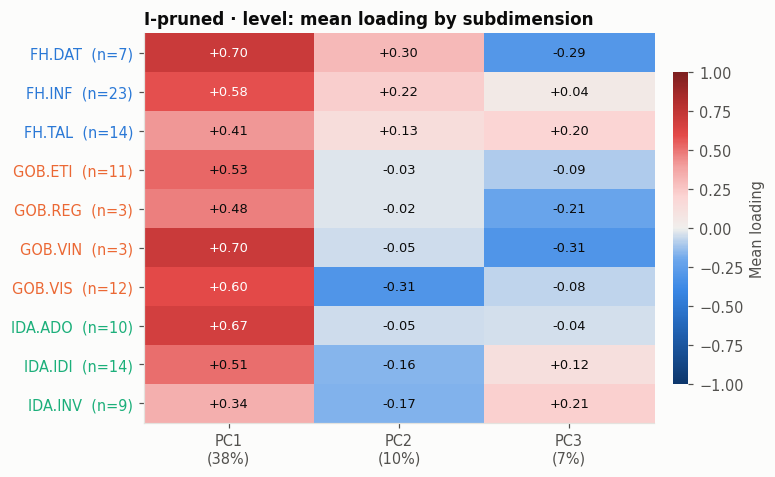

In [4]:
for cfg in PP.CONFIGS:
    Z, res, pa = fits[(cfg, "level")]
    k = PC.n_retained(pa)
    t = PP.tag(cfg, "level")
    print(f"\n### {cfg} · level")
    fig = PL.scree(pa, res.explained, f"{cfg} · level"); PL.save(fig, f"03_{t}_scree"); plt.show()
    fig = PL.biplot(res, codebook, f"{cfg} · level: countries on PC1–PC2"); PL.save(fig, f"03_{t}_biplot"); plt.show()
    for pc_ in ["PC1", "PC2"]:
        fig = PL.loading_bars(res, codebook, pc_, f"{cfg} · level: strongest loadings on {pc_}")
        PL.save(fig, f"03_{t}_loadings_{pc_}"); plt.show()
    fig = PL.subdim_loadings(res, codebook, max(k, 3), f"{cfg} · level: mean loading by subdimension")
    PL.save(fig, f"03_{t}_subdim_loadings"); plt.show()

## Profile view (overall level removed)


### A-full · profile


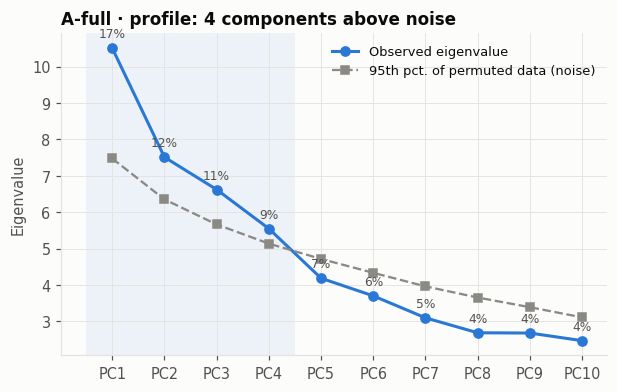

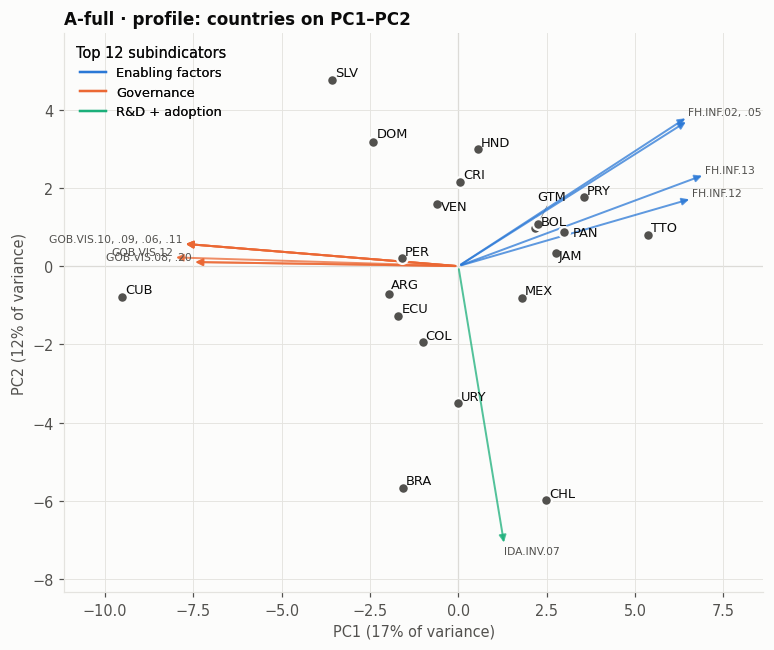

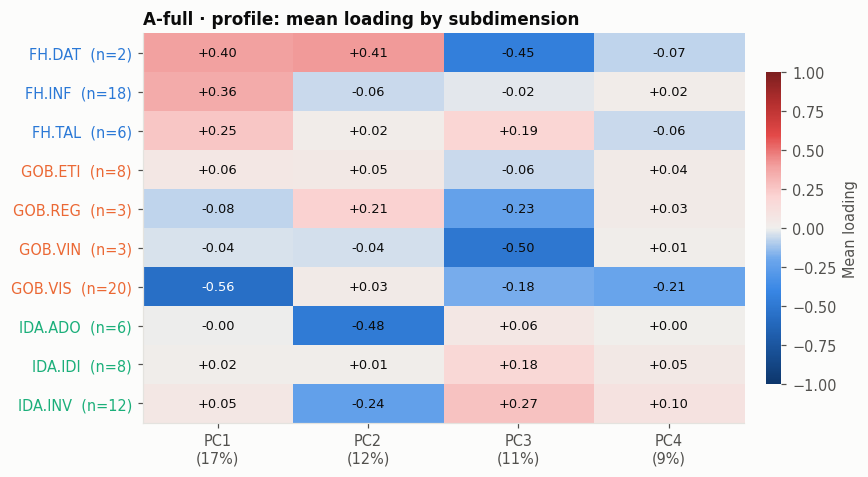


### A-pruned · profile


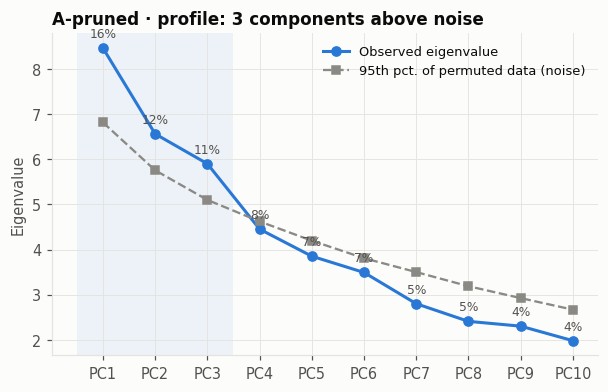

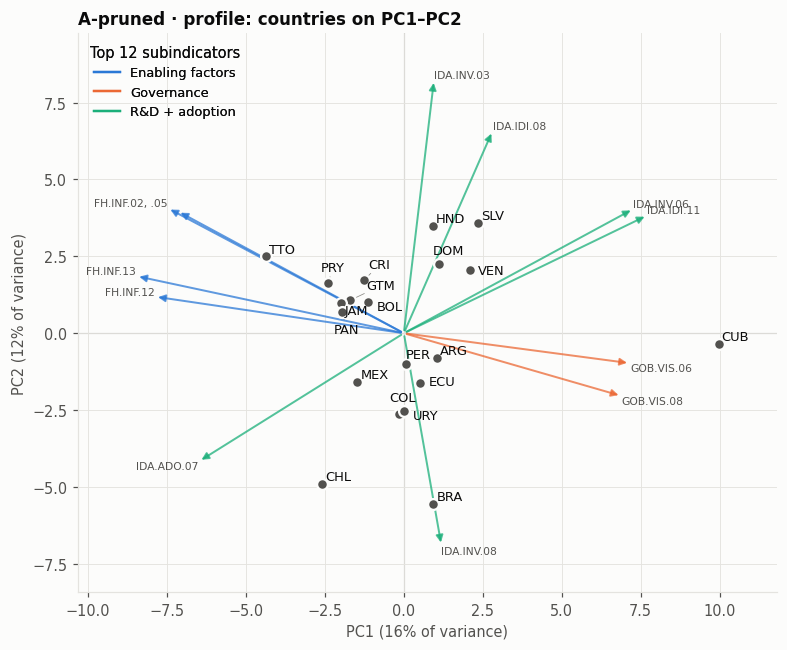

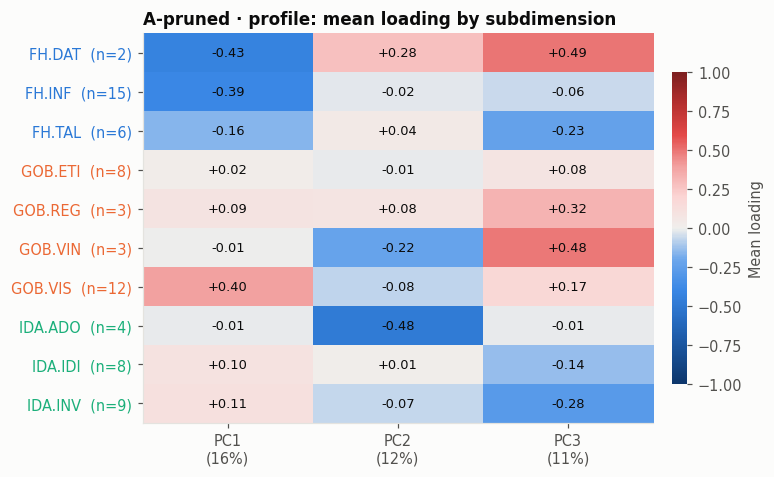


### I-full · profile


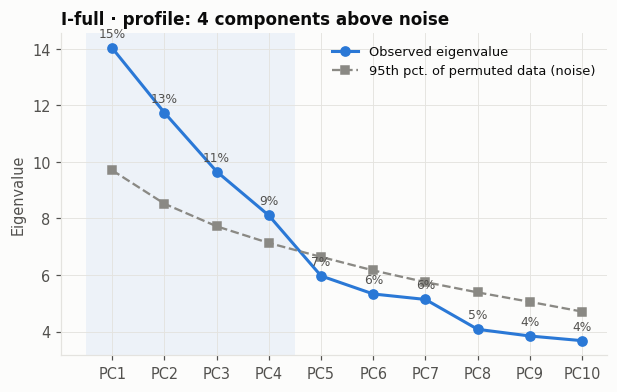

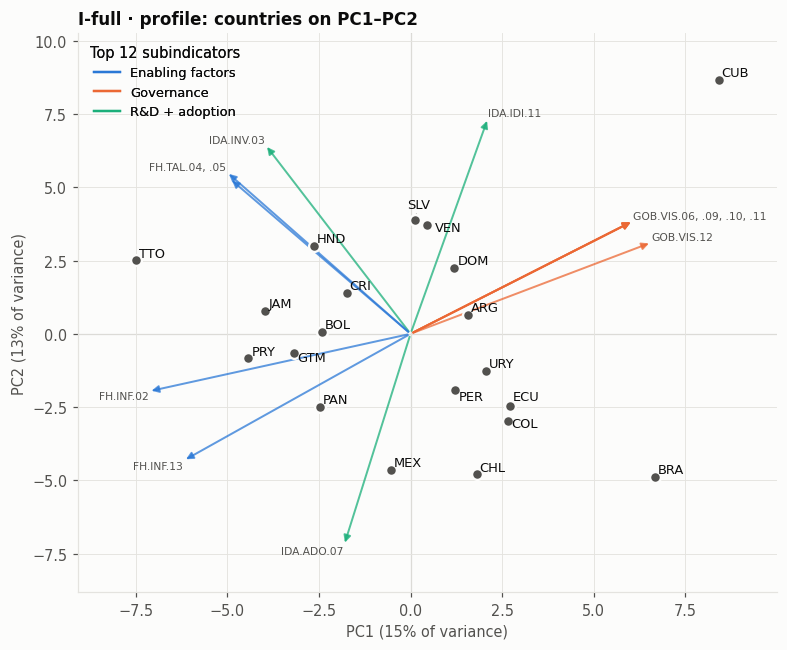

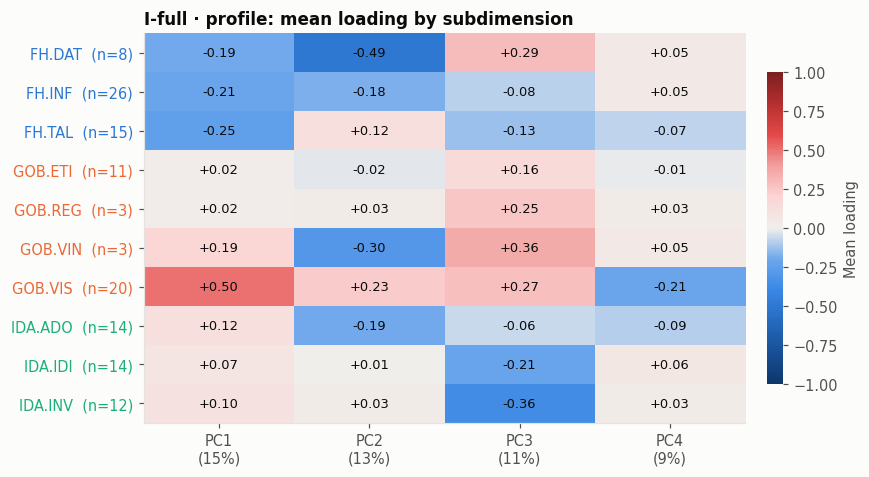


### I-pruned · profile


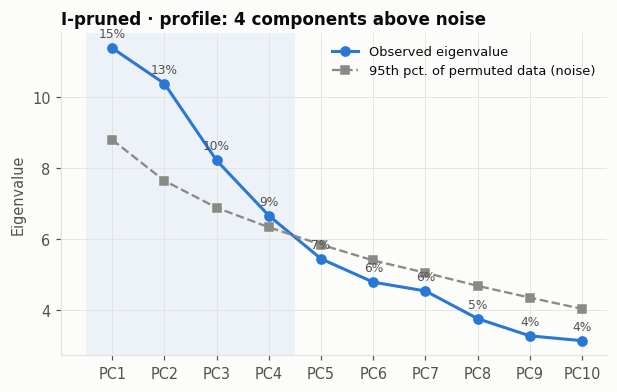

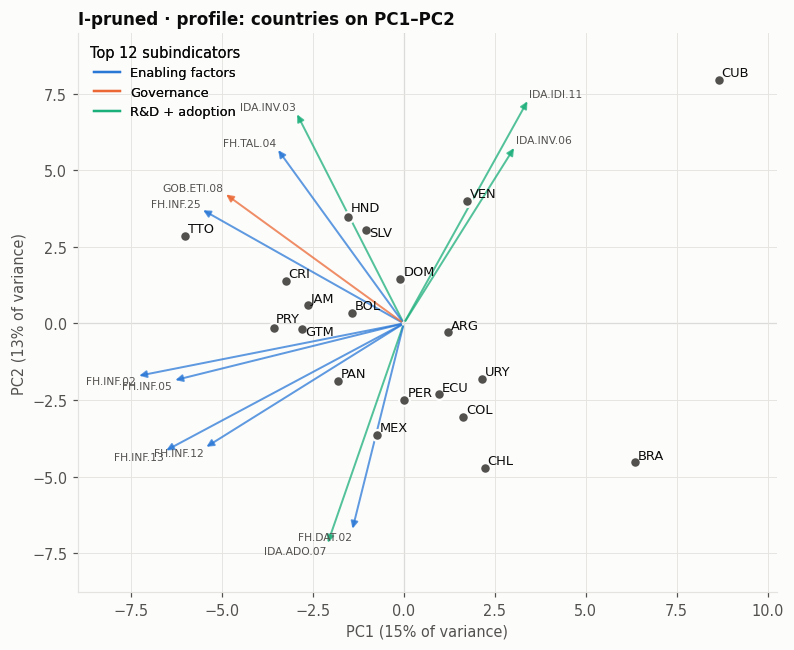

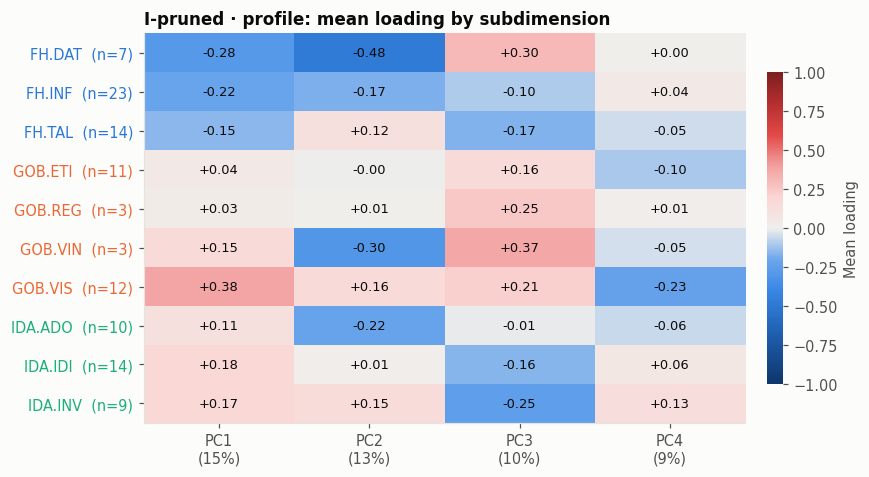

In [5]:
for cfg in PP.CONFIGS:
    Z, res, pa = fits[(cfg, "profile")]
    k = PC.n_retained(pa)
    t = PP.tag(cfg, "profile")
    print(f"\n### {cfg} · profile")
    fig = PL.scree(pa, res.explained, f"{cfg} · profile"); PL.save(fig, f"03_{t}_scree"); plt.show()
    fig = PL.biplot(res, codebook, f"{cfg} · profile: countries on PC1–PC2"); PL.save(fig, f"03_{t}_biplot"); plt.show()
    fig = PL.subdim_loadings(res, codebook, max(k, 3), f"{cfg} · profile: mean loading by subdimension")
    PL.save(fig, f"03_{t}_subdim_loadings"); plt.show()

## Reading the results

* **PC1 is each country's overall level.** It explains 36–39% of the variance in the level view, about 95% of subindicators load positively on it,
  and its scores correlate 0.997–0.998 with the country's mean z-score. Ordering countries on PC1 is essentially ranking them by their average.
* **Only two components stand out from noise** in every level configuration. After PC2 (10–12%), components are indistinguishable from what
  shuffled data produce with 20 countries.
* **PC2 contrasts national AI strategy and institutions (GOB.VIS) with infrastructure, data, talent and adoption.**
  Cuba is the extreme on the strategy side, followed by El Salvador and the Dominican Republic. Trinidad and Tobago, Paraguay, Panama and Chile
  lean to the capabilities side. (The sign of PC2 is arbitrary and flips between A and I; the content is the same.)
* **Profile view:** with the overall level removed, the variance spreads out (PC1 15–17%; 3–4 components above noise), and the strategy-versus-capabilities contrast is again the main axis.
* **Pruning changes little.** PC1 drops from 39% to 36% in A as redundant blocks go, and the loading patterns hold.